In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("death_clean.csv")
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [19]:
x = df[['Cause', 'Type']]
y = df[['Total Deaths']]

x_encoded = pd.get_dummies(x, columns=['Cause', 'Type'])

scaler = StandardScaler()
y_norm = scaler.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_norm, test_size=0.3, random_state=42)

In [20]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([ 9.74731445e-02, -1.49841309e-01, -3.23181152e-01, -2.42126465e-01,
       -1.65405273e-02, -1.65405273e-02, -1.49841309e-01,  4.39719273e+13,
       -5.08483887e-01, -4.36950684e-01, -5.63415527e-01,  2.50567627e+00,
       -1.49841309e-01,  3.52844238e-01,  1.53790283e+00, -1.49841309e-01,
       -1.09526711e+13,  2.50567627e+00, -4.84313965e-01, -3.84460449e-01,
       -3.79821777e-01,  8.42590332e-01,  9.67834473e-01, -4.88464355e-01,
       -1.49841309e-01, -5.62194824e-01, -5.63415527e-01, -4.12048340e-01,
       -2.97241211e-02, -2.97241211e-02, -4.92858887e-01, -1.48655171e+12,
       -1.12712155e+13, -1.49841309e-01, -3.90075684e-01, -1.49841309e-01,
        2.50567627e+00,  8.42590332e-01, -1.23962402e-01, -1.23962402e-01,
        9.74731445e-02, -5.44128418e-01, -4.86755371e-01, -1.49841309e-01,
       -3.90075684e-01,  1.24859619e+00, -1.65405273e-02, -2.97241211e-02,
       -4.33532715e-01, -2.97241211e-02, -3.79821777e-01, -4.36462402e-01,
       -5.44128418e-01,  

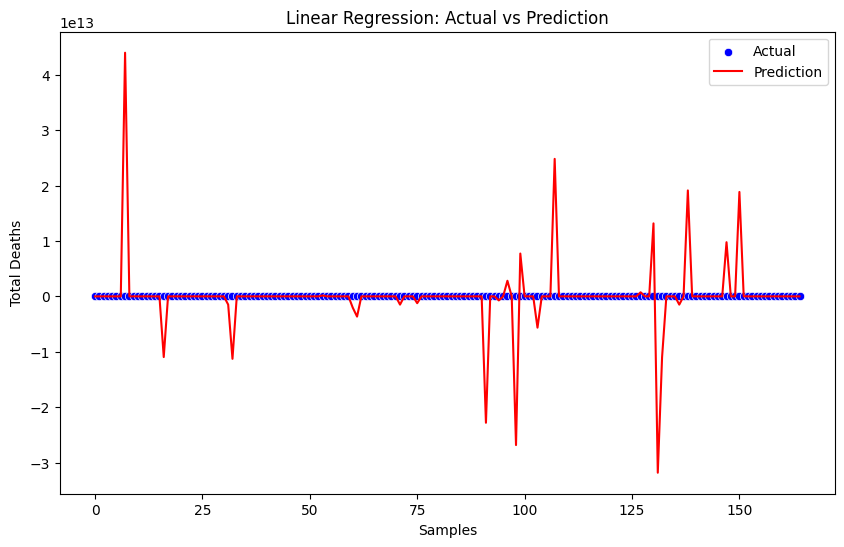

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=range(len(y_test)), y=y_test, color='blue', label='Actual')
sns.lineplot(x=range(len(y_test)), y=y_pred, color='red', label='Prediction')

plt.xlabel('Samples')
plt.ylabel('Total Deaths')
plt.title('Linear Regression: Actual vs Prediction')
plt.legend()
plt.show()

In [22]:
model.score(x_test, y_test)

-4.713759713703716e+25

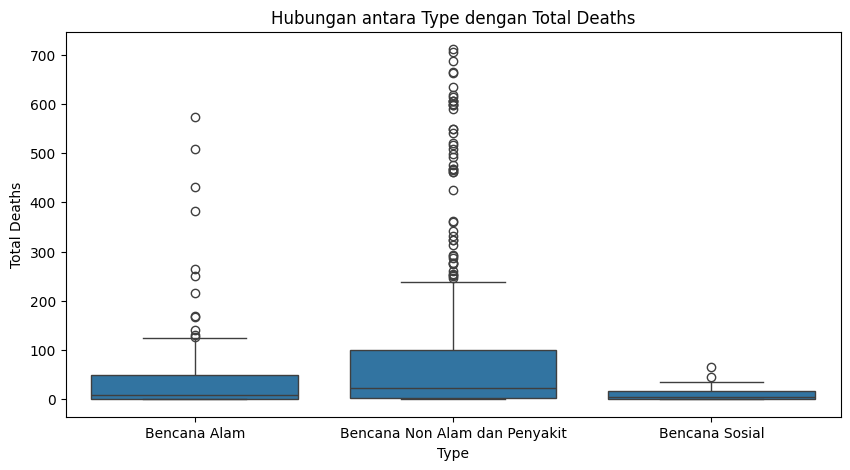

In [23]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Type', y='Total Deaths', data=df)
plt.title('Hubungan antara Type dengan Total Deaths')
plt.show()

STUDI KASUS DATA RANDOM

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

data_size = 50
experience = np.random.randint(1, 21, size=data_size)
education = np.random.randint(1, 5, size=data_size)  

noise = np.random.normal(0, 500000, size=data_size)  
salary = np.round(1000000 * experience + 500000 * education + noise).astype(int)

df = pd.DataFrame({
    'Experience': experience,
    'Education': education,
    'Salary': salary
})

df.head()

,Experience,Education,Salary
0,7,4,8661539
1,20,4,22305838
2,15,2,16515500
3,11,2,12465640
4,8,2,8580391


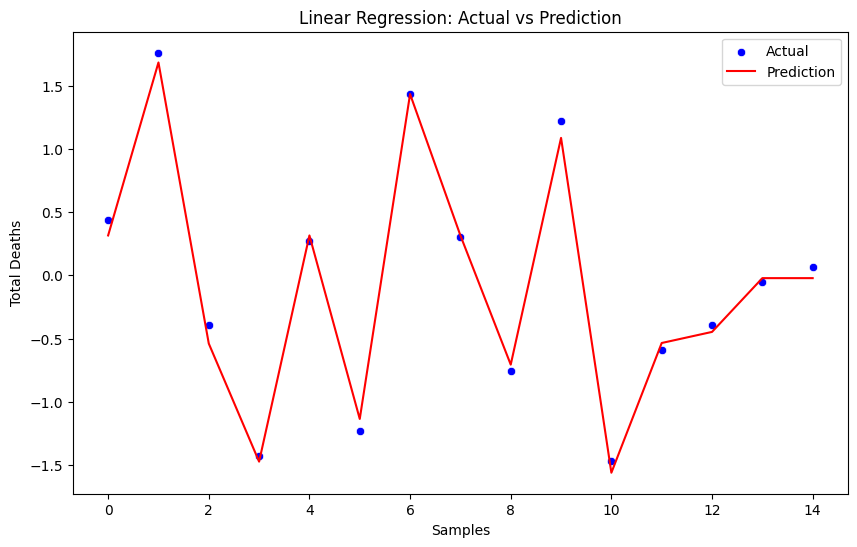

In [25]:
x = df[["Experience", "Education"]]
y = df[["Salary"]]

scaler_x = StandardScaler()
x_scaled = scaler_x.fit_transform(x)

scaler_y = StandardScaler()
y_norm = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_norm, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=range(len(y_test)), y=y_test, color='blue', label='Actual')
sns.lineplot(x=range(len(y_test)), y=y_pred, color='red', label='Prediction')

plt.xlabel('Samples')
plt.ylabel('Total Deaths')
plt.title('Linear Regression: Actual vs Prediction')
plt.legend()
plt.show()


In [26]:
model.score(x_test, y_test)

0.992814325133279

In [27]:
new_data = pd.DataFrame({
    'Experience': [1, 10, 5],
    'Education': [1, 2, 2]
})

new_data_scaled = scaler_x.transform(new_data)

prediction_norm = model.predict(new_data_scaled)
prediction = scaler_y.inverse_transform(prediction_norm.reshape(-1, 1))

new_data["Salary"] = np.round(prediction.flatten()).astype(int)

new_data

,Experience,Education,Salary
0,1,1,1332625
1,10,2,10928150
2,5,2,5871047


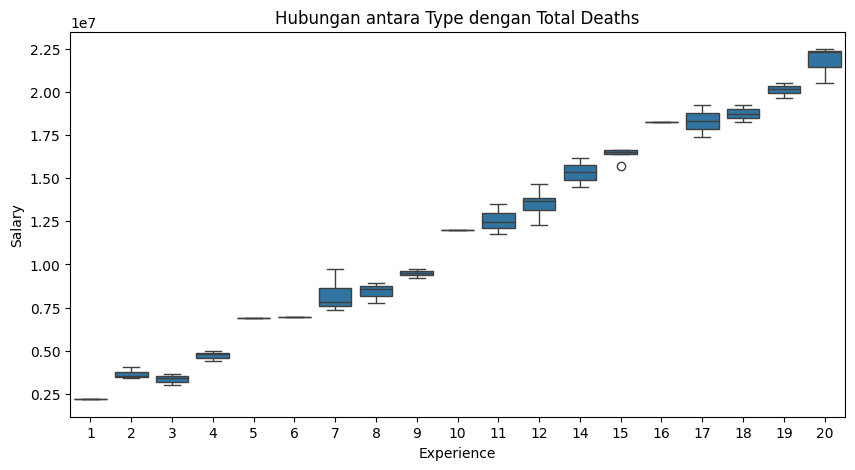

In [28]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Experience', y='Salary', data=df)
plt.title('Hubungan antara Type dengan Total Deaths')
plt.show()

In [29]:
new_data_scaled

array([[-1.72162018, -1.25033168],
       [-0.1501616 , -0.38204579],
       [-1.02319414, -0.38204579]])

In [30]:
prediction_norm

array([-1.81439246, -0.19312096, -1.04757526])

In [31]:
prediction_norm.reshape(-1, 1)

array([[-1.81439246],
       [-0.19312096],
       [-1.04757526]])

In [32]:
scaler_y.inverse_transform(prediction_norm.reshape(-1, 1))

array([[ 1332624.81195457],
       [10928150.30069915],
       [ 5871046.63752512]])

In [33]:
prediction.flatten()

array([ 1332624.81195457, 10928150.30069915,  5871046.63752512])

In [34]:
scaler_y.fit_transform(y).flatten()

array([-0.57609032,  1.72926681,  0.75092435,  0.06665515, -0.58980119,
       -0.71398716,  1.36765503,  0.23935596, -0.05250085, -1.29491345,
       -0.52788671, -1.46476575, -1.46402806,  0.44047842, -0.86290939,
       -1.44789176, -1.67108072,  0.27140233,  0.1874722 ,  1.21616206,
       -0.01504655,  1.04944872,  0.61146834,  0.73325963,  1.43150412,
        0.30064208,  1.43190219, -1.53162048, -0.87538397,  1.28535809,
       -0.39405018, -0.47820671, -0.7561668 ,  1.21280024, -1.20189524,
        0.69159802,  1.12595401, -0.39106176, -1.35550834,  1.75942368,
        0.77347611, -0.80002643,  0.03933513, -0.72702269,  0.77332185,
       -1.42613598,  0.41081509,  0.89744852, -1.22983905,  1.05069143])

In [35]:
y_norm

array([-0.57609032,  1.72926681,  0.75092435,  0.06665515, -0.58980119,
       -0.71398716,  1.36765503,  0.23935596, -0.05250085, -1.29491345,
       -0.52788671, -1.46476575, -1.46402806,  0.44047842, -0.86290939,
       -1.44789176, -1.67108072,  0.27140233,  0.1874722 ,  1.21616206,
       -0.01504655,  1.04944872,  0.61146834,  0.73325963,  1.43150412,
        0.30064208,  1.43190219, -1.53162048, -0.87538397,  1.28535809,
       -0.39405018, -0.47820671, -0.7561668 ,  1.21280024, -1.20189524,
        0.69159802,  1.12595401, -0.39106176, -1.35550834,  1.75942368,
        0.77347611, -0.80002643,  0.03933513, -0.72702269,  0.77332185,
       -1.42613598,  0.41081509,  0.89744852, -1.22983905,  1.05069143])